# Bike-Sharing Demand Analysis

How can a bike-sharing company place bicycles where demand actually is?

This notebook reruns the customer, calendar, and weather analysis, then records the findings and the operational actions. The full write-up is in `technical_report.md`. The team deck is `Bike Sharing Demand Analysis.pptx`.

## Questions

- At what hours is rental demand highest?
- Which days of the week have the highest demand?
- How do seasons influence rentals?
- How do weather conditions affect demand?
- How do casual and registered riders differ?
- Can historical data estimate later demand?


## Data

The inputs are `data/day.csv` (731 days) and `data/hour.csv` (17,379 hours), for Capital Bikeshare in Washington, D.C., from 2011 through 2012. `data/day_cleaned.csv` and `data/hour_cleaned.csv` are the shared copies: same rental counts, added labels, and humidity cleared where the source value is 0. Column meanings are in `DATA_DICTIONARY.md`.

Season codes in the source dictionary run in the opposite order from the dates. The scripts label code 1 as winter (21 Dec-20 Mar), code 2 as spring, code 3 as summer, and code 4 as fall. Weekday 0 is Sunday.

Averages are per day, or per observed hour. Eta-squared measures how much group averages account for rental variation. Temperature uses r-squared. The demand estimate is fit on days before 1 October 2012 and tested on the rest of 2012. The calendar-only model is the planning figure. The known-weather model also uses that day's weather, which is not available in advance.


In [1]:
%run Customer_analysis.py


CLEANED DATASET
Saved /Users/abhinavsingh/Git Repositories/Bike Sharing/Bike-Sharing-Demand-Analysis/data/day_cleaned.csv and /Users/abhinavsingh/Git Repositories/Bike Sharing/Bike-Sharing-Demand-Analysis/data/hour_cleaned.csv
Zero-humidity rows flagged: 22 hours

SEASON LABELS
Source dictionary names do not match the calendar.
Code 1 is labeled Winter here (21 Dec-20 Mar).
mnth         1   2   3   4   5   6   7   8   9   10  11  12
season_name                                                
Winter       62  57  40   0   0   0   0   0   0   0   0  22
Spring        0   0  22  60  62  40   0   0   0   0   0   0
Summer        0   0   0   0   0  20  62  62  44   0   0   0
Fall          0   0   0   0   0   0   0   0  16  62  60  40

CUSTOMER ANALYSIS: 2011-2012
----------------------------
Total rentals: 3,292,679
Casual: 620,017 (18.8%)
Registered: 2,672,662 (81.2%)
Note: These are rental transactions, not counts of unique customers.

AVERAGE RENTALS PER DAY
          casual  registered
d


AVERAGE RENTALS PER DAY BY SEASON
             casual  registered
season_name                    
Winter        334.9      2269.2
Spring       1106.1      3886.2
Summer       1202.6      4441.7
Fall          729.1      3999.1

AVERAGE RENTALS PER DAY BY MONTH
            casual  registered     cnt
month_name                            
January      194.2      1982.1  2176.3
February     262.5      2392.8  2655.3
March        716.8      2975.4  3692.3
April       1013.4      3471.5  4484.9
May         1214.3      4135.5  5349.8
June        1231.8      4540.6  5772.4
July        1260.6      4303.1  5563.7
August      1161.9      4502.5  5664.4
September   1172.0      4594.5  5766.5
October      963.9      4235.4  5199.2
November     610.0      3637.1  4247.2
December     349.9      3053.9  3403.8
Highest month: June
Lowest month: January

DATA LIMITS
                        check      value                                                                                                  


AVERAGE RENTALS PER DAY BY WEEKDAY
              casual  registered     cnt
weekday_name                            
Monday         674.1      3664.0  4338.1
Tuesday        556.2      3954.5  4510.7
Wednesday      551.1      3997.4  4548.5
Thursday       591.0      4076.3  4667.3
Friday         752.3      3938.0  4690.3
Saturday      1465.3      3085.3  4550.5
Sunday        1338.3      2890.5  4228.8
Highest total: Friday
Lowest total: Sunday

AVERAGE RENTALS BY SCHEDULE
             days  casual  registered     cnt
schedule                                     
Working day   500   606.6      3978.2  4584.8
Weekend       210  1401.8      2987.9  4389.7
Holiday        21  1064.7      2670.3  3735.0

AVERAGE RENTALS PER DAY BY YEAR
           casual  registered     cnt
year_name                            
2011        677.4      2728.4  3405.8
2012       1018.5      4581.5  5599.9



FACTOR INFLUENCE
                         factor                  scope  share_of_variation            low_group            high_group  low_mean  high_mean  mean_gap
                           Year          Daily rentals               0.321                 2011                  2012  3405.800   5599.900  2194.200
                         Season          Daily rentals               0.347               Winter                Summer  2604.100   5644.300  3040.200
              Weather situation          Daily rentals               0.099    Light rain / snow Clear / partly cloudy  1803.300   4876.800  3073.500
                    Day of week          Daily rentals               0.006               Sunday                Friday  4228.800   4690.300   461.500
Working day / weekend / holiday          Daily rentals               0.007              Holiday           Working day  3735.000   4584.800   849.800
                    Hour of day         Hourly rentals               0.501              


DONE
/Users/abhinavsingh/Git Repositories/Bike Sharing/Bike-Sharing-Demand-Analysis/charts
/Users/abhinavsingh/Git Repositories/Bike Sharing/Bike-Sharing-Demand-Analysis/results


## Patterns in time and rider type

Registered riders are 81.2% of the 3,292,679 rentals. Casual riders are 18.8%. Weekday casual share is 13.7%, and weekend casual share is 31.9%.

Weekday registered demand peaks at 08:00 and 17:00. Weekend registered demand peaks at 12:00, and weekend casual demand peaks at 14:00. The working-day peak stays at 17:00 after the 21 holidays are removed.

Friday averages 4,690 rentals and Sunday averages 4,229. Day of week explains 0.6% of daily variation. A working day averages 4,585, a weekend day 4,390, and a holiday 3,735.

Summer averages 5,644 rentals a day and winter averages 2,604. Spring averages 4,992 and fall averages 4,728. June is the highest month at 5,772 and January is the lowest at 2,176. Demand rises from 3,406 a day in 2011 to 5,600 in 2012.


In [2]:
%run weather_analysis.py

Daily data: (731, 16)
Hourly data: (17379, 17)

DATA LIMITS TO READ BEFORE THE WEATHER AVERAGES
Humidity is 0 on 2011-03-10 (22 hours).
That day stays in the rental totals and is removed from the humidity chart and correlation.
Missing hour rows: 165. Days with fewer than 20 hours: 8.
2012-10-29 has 22 rentals and 1 observed hour, coded as light rain/snow.
Severe weather hours:
    dteday  hr  cnt
2011-01-26  16   36
2012-01-09  18  164
2012-01-21   1   23
Daily rows coded severe weather: 0

WEATHER CORRELATIONS
                 sample    variable      r      p_value  days  significant_at_0_05
               all_days temperature  0.627 2.810622e-81   731                 True
               all_days    humidity -0.101 6.454143e-03   731                 True
               all_days  wind_speed -0.235 1.359959e-10   731                 True
excluding_zero_humidity temperature  0.628 2.924163e-81   730                 True
excluding_zero_humidity    humidity -0.115 1.922752e-03   730      


AVERAGE RENTALS BY WEATHER
weather
Clear              4876.8
Mist/Cloudy        4035.9
Light Rain/Snow    1803.3
Name: cnt, dtype: float64
Light rain/snow average without 29 Oct 2012: 1892.3
Light rain/snow days: 21

HOURLY RENTALS BY WEATHER
weather  Clear  Mist/Cloudy  Light Rain/Snow
hr                                          
0         59.2         47.2             28.1
1         34.4         35.5             17.1
2         22.8         25.5             14.8
3         12.0         12.5              6.9
4          6.4          6.7              4.7
5         20.4         20.1             13.9
6         79.2         74.6             56.0
7        218.7        224.7            131.1
8        361.4        391.3            213.8
9        226.4        226.8            129.0
10       192.5        159.5             77.8
11       234.3        182.7             85.8
12       282.0        225.9            137.3
13       283.4        225.9            116.1
14       269.5        208.7         

## Weather

Clear days average 4,877 rentals, mist or cloudy days 4,036, and light rain or snow 1,803. Light rain is about 37% of a clear day. The 17:00 peak remains in all three conditions.

Temperature has the strong linear association (r = 0.627, or 0.628 after the zero-humidity day is removed). Wind speed is r = -0.235. Humidity is r = -0.101, or -0.115 without 10 March 2011, which is -0.11 at two decimals. All three have p-values below 0.05. Severe weather is three hours and is not drawn as a curve.

Read the data-limit block above the weather averages. It covers the zero-humidity day, the 165 missing hour rows, and 29 October 2012.


,factor,scope,share_of_variation,low_group,high_group,low_mean,high_mean,mean_gap
0,Year,Daily rentals,0.321,2011,2012,3405.800,5599.900,2194.200
1,Season,Daily rentals,0.347,Winter,Summer,2604.100,5644.300,3040.200
2,Weather situation,Daily rentals,0.099,Light rain / snow,Clear / partly cloudy,1803.300,4876.800,3073.500
3,Day of week,Daily rentals,0.006,Sunday,Friday,4228.800,4690.300,461.500
4,Working day / weekend / holiday,Daily rentals,0.007,Holiday,Working day,3735.000,4584.800,849.800
5,Hour of day,Hourly rentals,0.501,4,17,6.400,461.500,455.100
6,Weather situation,Hourly rentals,0.021,Light rain / snow,Clear / partly cloudy,111.600,204.900,93.300
7,Temperature (r-squared),Daily rentals,0.394,Colder days,Warmer days,NaN,NaN,NaN
8,Customer type,Share of daily rentals,NaN,Weekday casual share,Weekend casual share,0.137,0.319,0.182


,model,test_days,mae,rmse,mean_actual,mean_predicted
0,Training average,92,1752.1,2060.9,5165.4,4415.1
1,Same date in 2011,92,1982.1,2306.2,5165.4,3402.2
2,"Calendar only, with year",92,1358.4,1714.1,5165.4,5902.5
3,"Known weather, without year",92,1742.5,1907.7,5165.4,3678.1
4,"Known weather, with year",92,885.2,1232.8,5165.4,5564.1
5,"Known weather, with year, excluding 29 Oct 2012",91,853.4,1174.6,5221.9,5583.5


,sample,variable,r,p_value,days,significant_at_0_05
0,all_days,temperature,0.627,2.810622e-81,731,True
1,all_days,humidity,-0.101,6.454143e-03,731,True
2,all_days,wind_speed,-0.235,1.359959e-10,731,True
3,excluding_zero_humidity,temperature,0.628,2.924163e-81,730,True
4,excluding_zero_humidity,humidity,-0.115,1.922752e-03,730,True
5,excluding_zero_humidity,wind_speed,-0.233,1.933490e-10,730,True


,month_name,casual,registered,cnt
0,January,194.2,1982.1,2176.3
1,February,262.5,2392.8,2655.3
2,March,716.8,2975.4,3692.3
3,April,1013.4,3471.5,4484.9
4,May,1214.3,4135.5,5349.8
5,June,1231.8,4540.6,5772.4
6,July,1260.6,4303.1,5563.7
7,August,1161.9,4502.5,5664.4
8,September,1172.0,4594.5,5766.5
9,October,963.9,4235.4,5199.2


'03_weekday_hours.png'

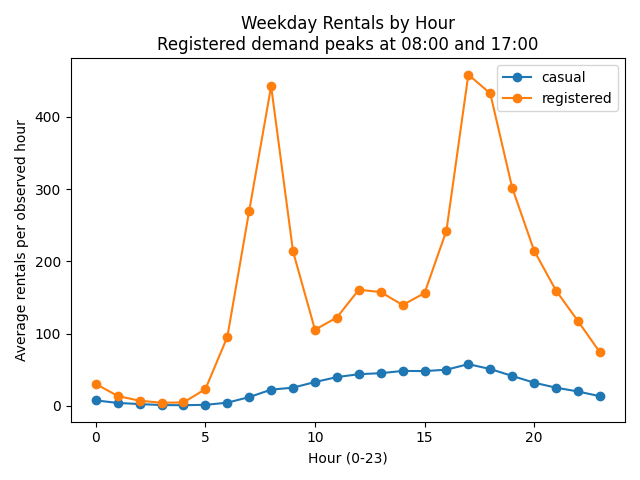

'04_weekend_hours.png'

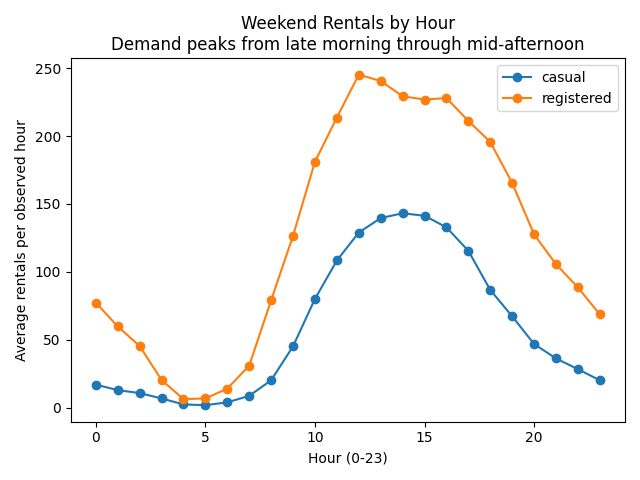

'05_seasons.png'

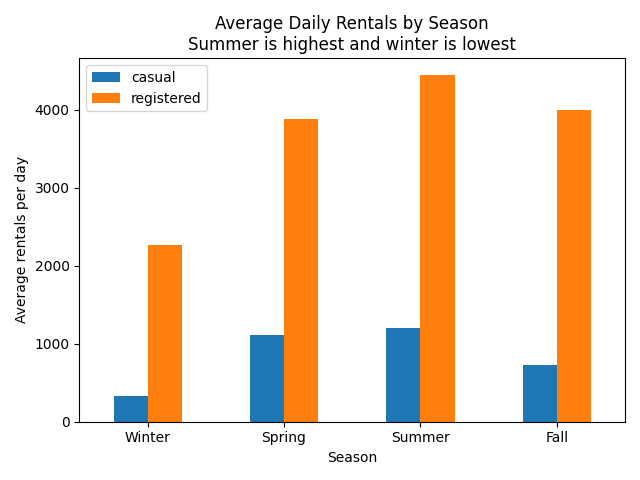

'17_month.png'

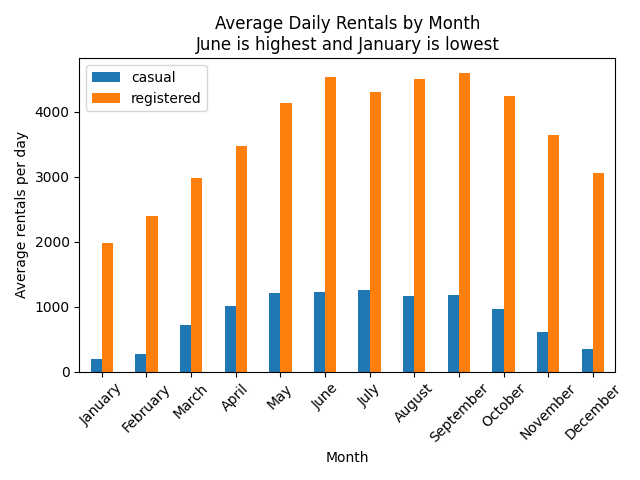

'07_day_of_week.png'

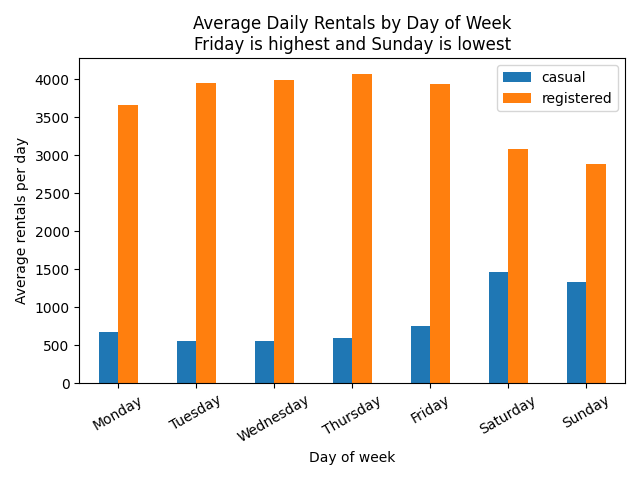

'08_schedule.png'

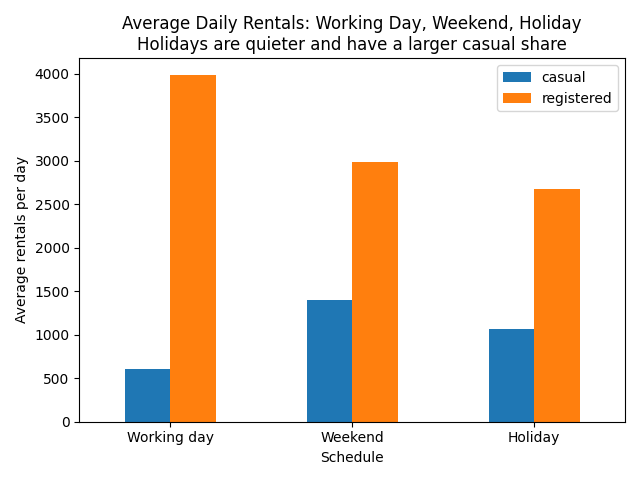

'09_year.png'

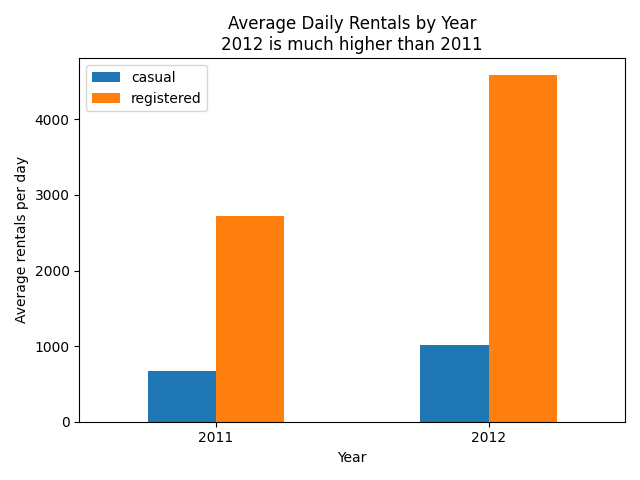

'06_weather.png'

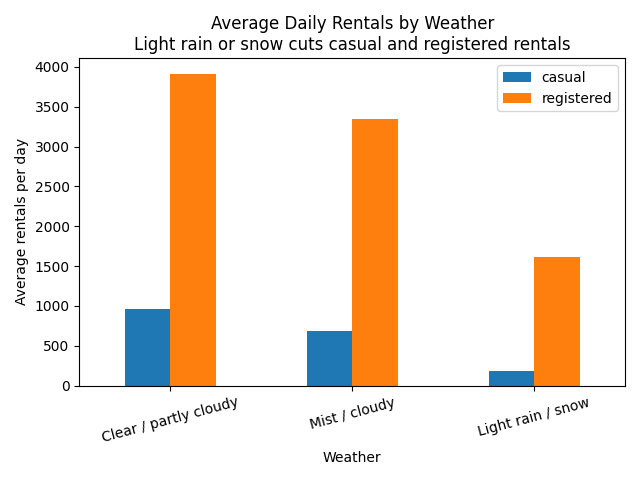

'10_factor_influence.png'

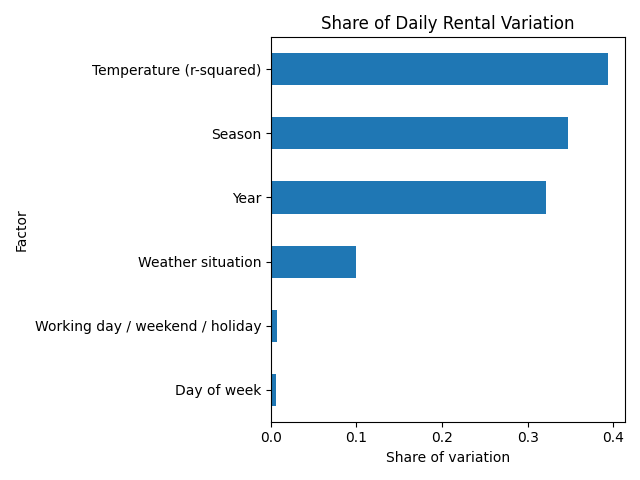

'15_hourly_weather.png'

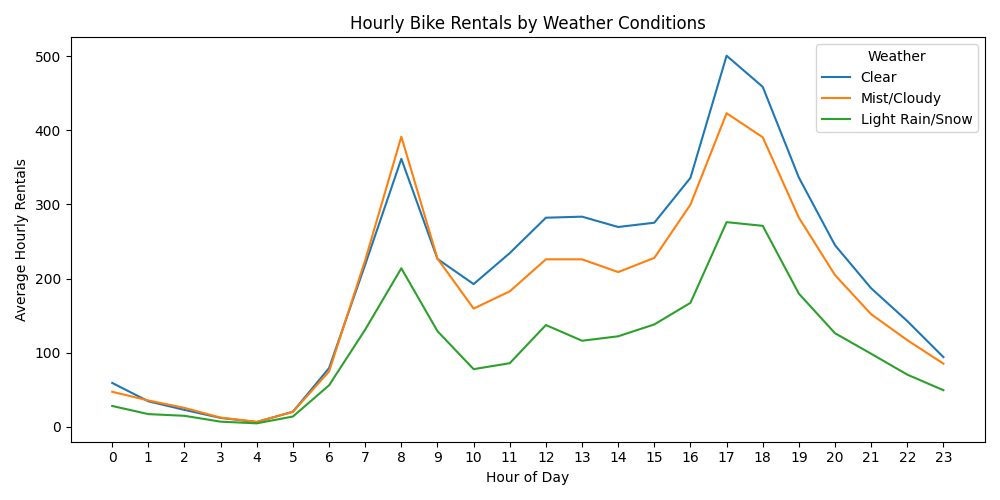

'12_temperature.png'

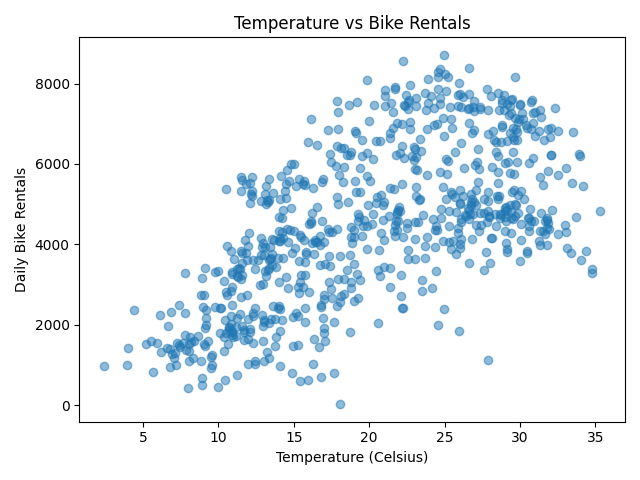

'11_forecast.png'

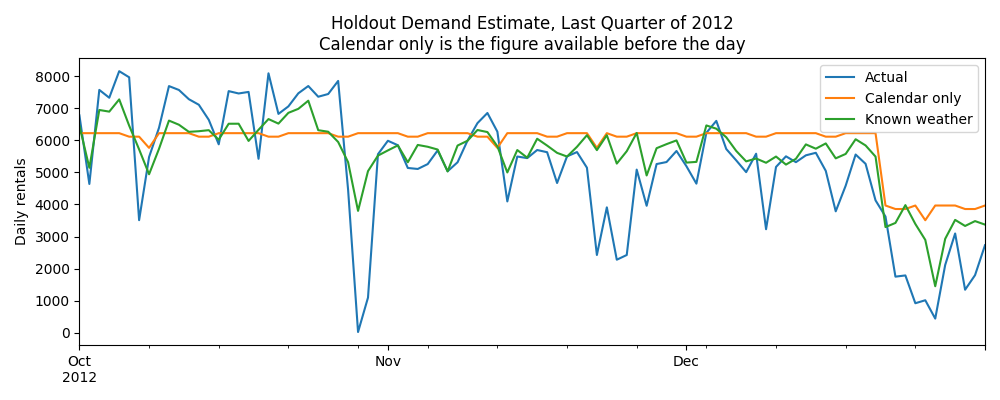

In [3]:
from IPython.display import Image, display
import pandas as pd

display(pd.read_csv("results/factor_influence.csv"))
display(pd.read_csv("results/forecast_metrics.csv"))
display(pd.read_csv("results/weather_correlations.csv"))
display(pd.read_csv("results/months.csv"))

for chart_name in [
    "03_weekday_hours.png",
    "04_weekend_hours.png",
    "05_seasons.png",
    "17_month.png",
    "07_day_of_week.png",
    "08_schedule.png",
    "09_year.png",
    "06_weather.png",
    "10_factor_influence.png",
    "15_hourly_weather.png",
    "12_temperature.png",
    "11_forecast.png",
]:
    display(chart_name)
    display(Image(filename=f"charts/{chart_name}"))


## Which factors matter, and can history estimate demand?

Hour of day explains 50.1% of hourly variation. Across days, temperature explains 39.4%, season 34.7%, and year 32.1%. Weather situation explains 9.9%: the gap between clear and light rain is about 3,074 rentals, and only 21 days fall in the light-rain group. Day of week and the holiday split each explain under 1% of the daily total. Customer type changes the mix of riders.

On the last 92 days of 2012 the actual mean is 5,165. The calendar-only model, using year, season, holiday, and working day, has a mean absolute error of 1,358 and predicts 5,903. That is the planning figure. The training average is off by 1,752 and the same date in 2011 by 1,982. Adding that day's weather lowers the error to 885 and the prediction to 5,564. That weather is not known in advance, so 885 is not the advance-forecast error. Without year, even with known weather, the model predicts 3,678. This is a system-wide daily estimate. The file has no station locations.

## Recommendations

1. On working days, move bicycles into commute positions before 08:00 and again before 17:00. On weekends, stage bicycles for late morning through mid-afternoon, when casual demand peaks around 14:00.
2. Run the largest fleet in summer and the smallest in winter, using the calendar season names above. June is the busiest month and January is the quietest.
3. On a light-rain forecast, plan for about 1,800 rentals and still cover 17:00. Use temperature in the daily plan. Treat a named storm separately: 29 October 2012 produced 22 rentals.
4. Set the base fleet from the 2012 level, about 5,600 rentals a day. Staff holidays nearer 3,735 rentals, with a larger casual share, rather than as a normal working day.

The same findings and actions are written up in `technical_report.md`.
